# 16 · Bioreactors and enzyme kinetics

Enzymes are catalysts with a rate law of their own - saturating, inhibitable - and living cells are catalysts
that make more of themselves. This notebook fits Michaelis-Menten kinetics to initial-rate data (and shows
why the classic linearised plots mislead), models growth with Monod kinetics in batch, chemostat and
fed-batch reactors, and finds the dilution rate at which a chemostat washes out and the one at which it
produces most.

**What you will learn**
- fit Michaelis-Menten kinetics correctly
- recognise inhibition types
- model batch, chemostat and fed-batch growth
- find washout and the optimum dilution rate

**Before you start:** notebooks 05 and 10  ·  **Time:** about 60-75 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import bio, datasets
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Michaelis-Menten kinetics from initial rates

Lineweaver-Burk: V_max = 1.828, K_m = 0.357
Hanes-Woolf:     V_max = 1.766, K_m = 0.294
nonlinear:       V_max = 1.845 +/- 0.051, K_m = 0.350 +/- 0.037   (true 1.8, 0.35)


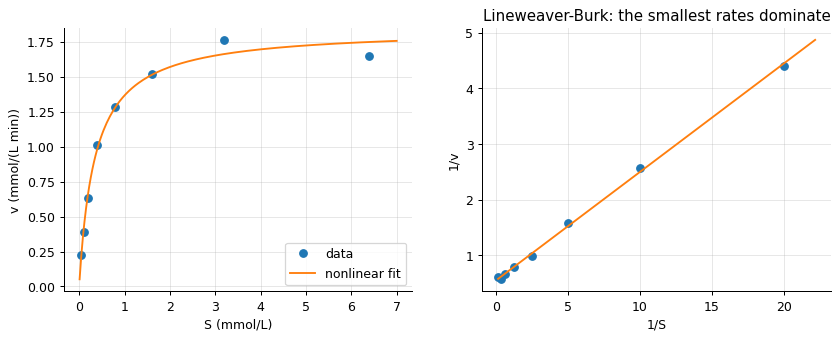

In [2]:
d = pd.read_csv(datasets.path("enzyme_initial_rates.csv"), comment="#")
S, v = d.S_mmol_L.to_numpy(), d.v_mmol_L_min.to_numpy()
lb, hw, nl = bio.lineweaver_burk(S, v), bio.hanes_woolf(S, v), bio.fit_michaelis_menten(S, v)
print(f"Lineweaver-Burk: V_max = {lb['V_max']:.3f}, K_m = {lb['K_m']:.3f}")
print(f"Hanes-Woolf:     V_max = {hw['V_max']:.3f}, K_m = {hw['K_m']:.3f}")
print(f"nonlinear:       V_max = {nl['V_max']:.3f} +/- {nl['se_V_max']:.3f}, K_m = {nl['K_m']:.3f} +/- {nl['se_K_m']:.3f}   (true 1.8, 0.35)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
Sf = np.linspace(0.01, 7, 200)
ax[0].plot(S, v, "o", label="data"); ax[0].plot(Sf, bio.michaelis_menten(Sf, nl["V_max"], nl["K_m"]), label="nonlinear fit"); ax[0].set(xlabel="S (mmol/L)", ylabel="v (mmol/(L min))"); ax[0].legend()
ax[1].plot(1 / S, 1 / v, "o"); ax[1].plot(1 / Sf[Sf > 0.04], 1 / bio.michaelis_menten(Sf[Sf > 0.04], lb["V_max"], lb["K_m"])); ax[1].set(xlabel="1/S", ylabel="1/v", title="Lineweaver-Burk: the smallest rates dominate"); plt.show()

Lineweaver-Burk straightens the hyperbola but weights the points with the smallest rates - the least
precise - most heavily, and its $K_m$ is off by a third here; Hanes-Woolf is better, and nonlinear regression
on the untransformed data is right, with standard errors. The linearised plots are for looking, not for
reporting - the same conclusion as notebook 05 for rate laws.

## Inhibition

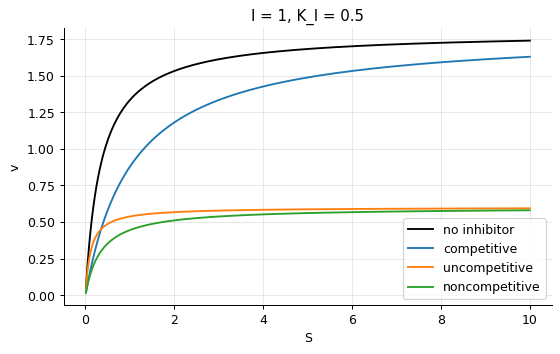

competitive: same V_max, higher apparent K_m (overcome by more substrate); noncompetitive: lower V_max; uncompetitive: both lower


In [3]:
Sf = np.linspace(0.01, 10, 300)
fig, ax = plt.subplots()
ax.plot(Sf, bio.michaelis_menten(Sf, 1.8, 0.35), "k", label="no inhibitor")
for kind in ("competitive", "uncompetitive", "noncompetitive"):
    ax.plot(Sf, bio.michaelis_menten(Sf, 1.8, 0.35, inhibitor=1.0, K_I=0.5, inhibition=kind), label=kind)
ax.set(xlabel="S", ylabel="v", title="I = 1, K_I = 0.5"); ax.legend(); plt.show()
print("competitive: same V_max, higher apparent K_m (overcome by more substrate); noncompetitive: lower V_max; uncompetitive: both lower")

A competitive inhibitor competes for the active site and can be out-competed by substrate; a
noncompetitive one disables the enzyme wherever it binds; an uncompetitive one binds only the
enzyme-substrate complex. Drug design is largely the design of inhibitors, and their type is read from how
the apparent $V_{max}$ and $K_m$ shift.

## Monod growth in a batch culture

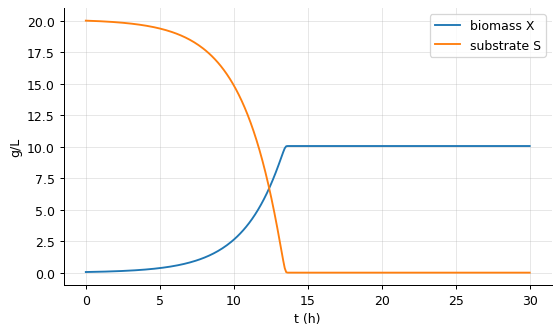

lag-free exponential growth at mu_max: doubling time 1.73 h; final biomass 10.05 g/L = X0 + Y S0 = 10.05


In [4]:
mu_max, K_s, Y = 0.4, 0.2, 0.5                                     # 1/h, g/L, g cells per g substrate
t = np.linspace(0, 30, 300)
bg = bio.batch_growth(0.05, 20.0, mu_max, K_s, Y, t)
fig, ax = plt.subplots(); ax.plot(t, bg["X"], label="biomass X"); ax.plot(t, bg["S"], label="substrate S"); ax.set(xlabel="t (h)", ylabel="g/L"); ax.legend(); plt.show()
print(f"lag-free exponential growth at mu_max: doubling time {np.log(2)/mu_max:.2f} h; final biomass {bg['X'][-1]:.2f} g/L = X0 + Y S0 = {0.05 + Y * 20:.2f}")

Monod's law is Michaelis-Menten for cells: growth is exponential while substrate is plentiful and stops when
it is gone, and the yield coefficient fixes how much biomass a gram of substrate makes. Real cultures add a
lag phase, death, and product inhibition (ethanol stops yeast at about 12 %), but Monod is the skeleton.

## The chemostat: steady growth, washout and the optimum

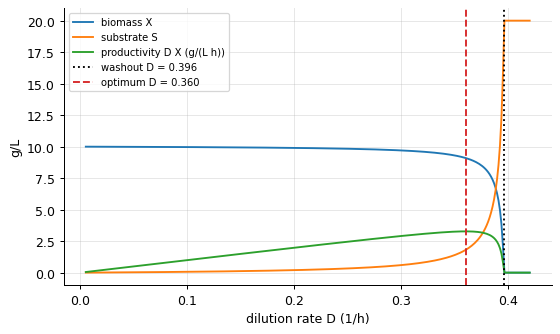

at D = 0.2 1/h: S = 0.200 g/L, X = 9.90 g/L; the culture washes out above D = 0.396 1/h


In [5]:
S_in = 20.0
Ds = np.linspace(0.005, 0.42, 300)
ss = [bio.chemostat_steady(D, S_in, mu_max, K_s, Y) for D in Ds]
X_ss, S_ss, prod = np.array([s["X"] for s in ss]), np.array([s["S"] for s in ss]), np.array([s.get("productivity", 0.0) for s in ss])
D_wash, D_opt = bio.chemostat_washout(mu_max, K_s, S_in), bio.chemostat_optimum(mu_max, K_s, S_in)
fig, ax = plt.subplots(); ax.plot(Ds, X_ss, label="biomass X"); ax.plot(Ds, S_ss, label="substrate S"); ax.plot(Ds, prod, label="productivity D X (g/(L h))")
ax.axvline(D_wash, color="k", ls=":", label=f"washout D = {D_wash:.3f}"); ax.axvline(D_opt, color="C3", ls="--", label=f"optimum D = {D_opt:.3f}"); ax.set(xlabel="dilution rate D (1/h)", ylabel="g/L"); ax.legend(fontsize=8); plt.show()
print(f"at D = 0.2 1/h: S = {bio.chemostat_steady(0.2, S_in, mu_max, K_s, Y)['S']:.3f} g/L, X = {bio.chemostat_steady(0.2, S_in, mu_max, K_s, Y)['X']:.2f} g/L; the culture washes out above D = {D_wash:.3f} 1/h")

In a chemostat the cells grow exactly as fast as they are washed out, $\mu(S) = D$, so the substrate
concentration is set by the dilution rate and the biomass by the yield. Too fast a dilution and the culture
cannot keep up: washout, sharp and total. The productivity has a maximum just below washout - the
operating point of a continuous fermenter, run with a margin, because the cliff is close.

## Fed-batch

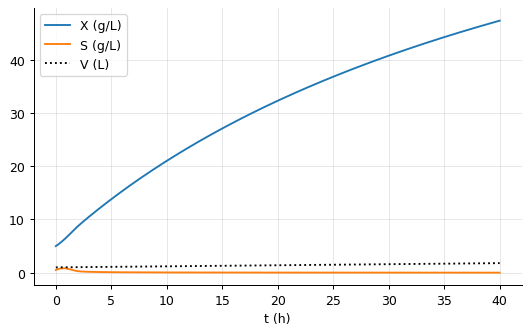

substrate stays low (0.836 g/L at most) while the biomass rises to 47.4 g/L in a volume of 1.8 L


In [6]:
fb = bio.fed_batch(X0=5.0, S0=0.5, V0=1.0, S_feed=200.0, F=0.02, mu_max=mu_max, K_s=K_s, Y_xs=Y, t=np.linspace(0, 40, 400))
fig, ax = plt.subplots(); ax.plot(fb["t"], fb["X"], label="X (g/L)"); ax.plot(fb["t"], fb["S"], label="S (g/L)"); ax.plot(fb["t"], fb["V"], "k:", label="V (L)"); ax.set(xlabel="t (h)"); ax.legend(); plt.show()
print(f"substrate stays low ({fb['S'].max():.3f} g/L at most) while the biomass rises to {fb['X'][-1]:.1f} g/L in a volume of {fb['V'][-1]:.1f} L")

Feeding concentrated substrate slowly keeps its concentration low - avoiding overflow metabolism, oxygen
limitation and substrate inhibition - while the biomass accumulates to densities a batch cannot reach. Baker's
yeast, penicillin and most therapeutic proteins are made this way; the feed profile is the process.

## Inside the algorithm: the chemostat steady state

In [7]:
D_ = 0.2
S_ss_hand = K_s * D_ / (mu_max - D_)
print("by hand: S =", S_ss_hand, "X =", Y * (S_in - S_ss_hand), "; library:", bio.chemostat_steady(D_, S_in, mu_max, K_s, Y))

by hand: S = 0.20000000000000004 X = 9.9 ; library: {'S': 0.20000000000000004, 'X': 9.9, 'washout': False, 'productivity': 1.9800000000000002}


## Exercises
1. Include a maintenance term m_s = 0.02 g substrate/(g cells h) and a death rate k_d = 0.01 1/h in the batch growth model, and show how they change the final biomass and the stationary phase.
2. Two chemostats in series (each D = 0.3 1/h relative to its own volume): compute the outlet substrate and biomass, and compare the total residence time for 99 % substrate conversion with a single chemostat.
3. **Implement it yourself:** integrate the batch enzyme reactor dS/dt = -V_max S/(K_m + S) with solve_ivp and compare with `bio.batch_enzyme` at 5 time points.